In [1]:
!pip install seaborn

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler,LabelEncoder
from sklearn.model_selection import train_test_split


In [3]:
df= sns.load_dataset("titanic")
print(df.head())

   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True  
3  woman       False    C  Southampton   yes  False  
4    man        True  NaN  Southampton    no   True  


In [4]:
df = df.drop_duplicates()
df = df.drop(columns=["deck", "embark_town", "alive", "class"])

In [5]:
df["age"]= df["age"].fillna(df["age"].median())
df["embarked"]= df["embarked"].fillna(df["embarked"].mode()[0])
df = df.dropna()

In [6]:
df["sex"]= LabelEncoder().fit_transform(df["sex"])
df=pd.get_dummies (df,columns=["embarked","who"],drop_first = True)

In [7]:
cols = ["age","fare","sibsp","parch"]
df[cols]= StandardScaler().fit_transform(df[cols])

In [8]:
print(df.describe())
print(df.corr(numeric_only=True))

         survived      pclass         sex           age         sibsp  \
count  784.000000  784.000000  784.000000  7.840000e+02  7.840000e+02   
mean     0.411990    2.243622    0.626276  1.540718e-16 -4.984675e-17   
std      0.492507    0.855056    0.484101  1.000638e+00  1.000638e+00   
min      0.000000    1.000000    0.000000 -2.129540e+00 -5.305986e-01   
25%      0.000000    1.000000    0.000000 -5.573596e-01 -5.305986e-01   
50%      0.000000    3.000000    1.000000 -1.020247e-01 -5.305986e-01   
75%      1.000000    3.000000    1.000000  4.625904e-01  4.840095e-01   
max      1.000000    3.000000    1.000000  3.668148e+00  7.586267e+00   

              parch          fare  
count  7.840000e+02  7.840000e+02  
mean   2.039185e-17 -6.910572e-17  
std    1.000638e+00  1.000638e+00  
min   -4.971569e-01 -6.659087e-01  
25%   -4.971569e-01 -5.114778e-01  
50%   -4.971569e-01 -3.608837e-01  
75%    6.984597e-01 -1.155622e-02  
max    6.676543e+00  9.162595e+00  
            surviv

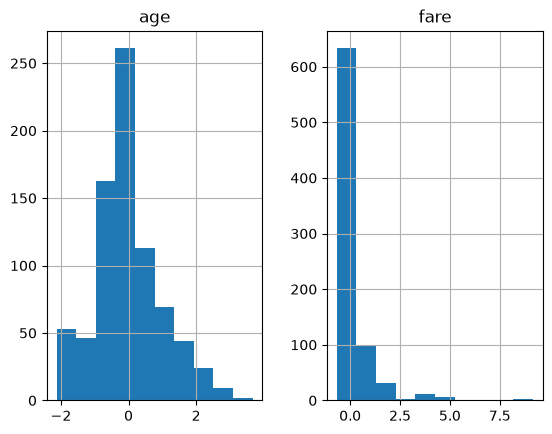

In [9]:
df[["age","fare",]].hist()
plt.show()

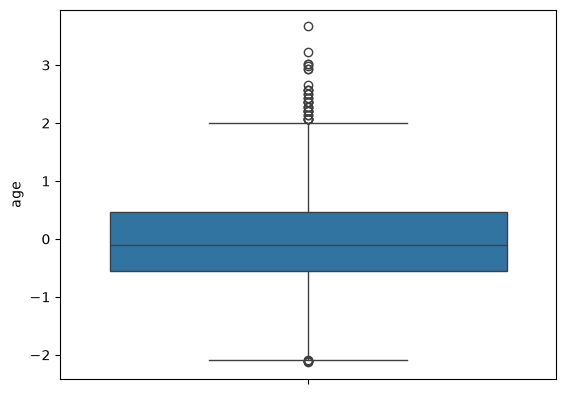

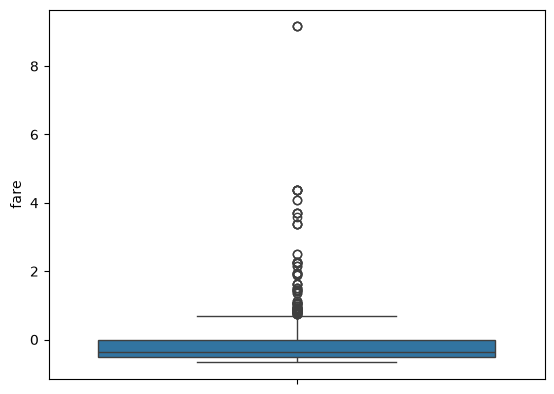

In [10]:
sns.boxplot(y=df["age"])
plt.show()
sns.boxplot(y=df["fare"])
plt.show()

In [12]:
x=df.drop("survived",axis=1)
y=df["survived"]
x_train,x_test,y_train,Y_test = train_test_split(x,y,test_size=0.2,random_state=42)
print("training:",x_train.shape)
print("testing:",x_test.shape)

training: (627, 12)
testing: (157, 12)
